# What makes a house expensive?### Multivariate Linear Regression · from scratch · ≈ 2 hoursLast lecture you watched the matrix form of linear regression take shape on the board — one row of weights, one matrix of features, and the whole dataset's predictions tumble out in a single multiplication. Today you'll turn that math into working code and point it at a real dataset: **house prices in California**.Eight numbers describe each neighborhood — median income, number of rooms, how old the houses are, latitude, longitude, and so on. From those eight numbers, you'll predict the median house value. Your model will be a vector of eight weights that says, in effect: *"here is how much each thing matters."*### What you will build1. A `MultivariateLinearRegression` class with vectorized `fit` and `predict`2. A loss curve that proves gradient descent is doing its job3. **A learning-rate playground** — the single most important hyperparameter in all of ML4. A ranked feature-importance plot answering the question the title asks### Ground rules- Only **NumPy**, **Matplotlib**, and sklearn (for data loading and the final comparison)- No `sklearn.linear_model.LinearRegression` until the very last section- Keep your math vectorized. If you find yourself writing a `for` loop over training examples, stop and think about how a matrix multiply would do the same thing in one line.Let's build.

---## 1. Setup

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

np.random.seed(42)
plt.rcParams["figure.figsize"] = (9, 5)
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

---## 2. The dataThe **California Housing** dataset: 20,640 California census blocks, each described by 8 features. The target is the **median house value** in that block, in units of $100,000.| Feature | What it is ||---|---|| `MedInc` | median income in the block (tens of thousands) || `HouseAge` | median house age (years) || `AveRooms` | average rooms per household || `AveBedrms` | average bedrooms per household || `Population` | block population || `AveOccup` | average household occupants || `Latitude` | geographic latitude || `Longitude` | geographic longitude |Before you train anything, go look at the data. Which features are on wildly different scales? Which ones do you expect to matter? Write down two guesses before you see the answer in Section 6.

In [ ]:
housing = fetch_california_housing()
X = housing.data
y = housing.target
feature_names = housing.feature_names

print(f"Features: {X.shape},   Target: {y.shape}")
print(f"Feature names: {feature_names}")
print(f"\nFirst 3 rows:\n{X[:3]}")
print(f"\nTarget range: ${y.min()*100:.0f}k  —  ${y.max()*100:.0f}k")

Features: (20640, 8),   Target: (20640,)
Feature names: ['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup', 'Latitude', 'Longitude']

First 3 rows:
[[ 8.32520000e+00  4.10000000e+01  6.98412698e+00  1.02380952e+00
   3.22000000e+02  2.55555556e+00  3.78800000e+01 -1.22230000e+02]
 [ 8.30140000e+00  2.10000000e+01  6.23813708e+00  9.71880492e-01
   2.40100000e+03  2.10984183e+00  3.78600000e+01 -1.22220000e+02]
 [ 7.25740000e+00  5.20000000e+01  8.28813559e+00  1.07344633e+00
   4.96000000e+02  2.80225989e+00  3.78500000e+01 -1.22240000e+02]]

Target range: $15k  —  $500k


### 2.1 Why standardization is not optional hereLook at the scales. `MedInc` is around 3–8; `Population` is in the thousands; `Latitude` is 32–42. If you feed these to gradient descent as-is, the gradient for `Population` will dominate — not because population matters more, but because its numbers are bigger. The learning rate that works for one feature will overshoot for another.**Task:** Split the data 80/20 (random_state=42), then standardize the features. Fit the scaler on the training set only.

In [ ]:
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(f"Train: {X_train_scaled.shape},  Test: {X_test_scaled.shape}")
print(f"Train means (should all be ~0): {X_train_scaled.mean(axis=0).round(3)}")
print(f"Train stds  (should all be ~1): {X_train_scaled.std(axis=0).round(3)}")

Train: (16512, 8),  Test: (4128, 8)
Train means (should all be ~0): [-0. -0.  0. -0. -0. -0.  0. -0.]
Train stds  (should all be ~1): [1. 1. 1. 1. 1. 1. 1. 1.]


---## 3. Build itHere is the math from the lecture, in one place.**Hypothesis** (for the whole training set at once):$$h_\theta(X) = X\theta + b$$**Cost** (half-mean-squared-error):$$J(\theta) = \frac{1}{2m}\sum_{i=1}^{m}\left(h_\theta(x^{(i)}) - y^{(i)}\right)^2$$**Gradient** (for every weight at once):$$\frac{\partial J}{\partial\theta} = \frac{1}{m}X^T(h_\theta(X) - y)$$**Update:** $\theta \leftarrow \theta - \alpha \cdot \nabla J$Your class should expose `fit`, `predict`, and keep a `loss_history`. Beyond that, how you structure it is up to you. Keep it vectorized — any `for` loop over training examples is a bug.

In [ ]:
class MultivariateLinearRegression:
    def __init__(self, learning_rate=0.01, n_iterations=1000):
        self.learning_rate = learning_rate
        self.n_iterations = n_iterations
        self.loss_history = []
        self.theta = None
        self.b = 0.0

    def fit(self, X, y):
        m, n = X.shape
        self.theta = np.zeros(n)
        self.b = 0.0
        self.loss_history = []

        for _ in range(self.n_iterations):
            # Hypothesis prediction
            y_pred = X.dot(self.theta) + self.b
            error = y_pred - y

            # Cost calculation
            cost = (1 / (2 * m)) * np.sum(error ** 2)
            self.loss_history.append(cost)

            # Check for divergence
            if np.isnan(cost) or np.isinf(cost):
                break

            # Gradients
            d_theta = (1 / m) * X.T.dot(error)
            d_b = (1 / m) * np.sum(error)

            # Updates
            self.theta -= self.learning_rate * d_theta
            self.b -= self.learning_rate * d_b

        return self

    def predict(self, X):
        return X.dot(self.theta) + self.b

---## 4. First training runTrain with `learning_rate=0.1` and `n_iterations=1000`. Then plot the loss curve.

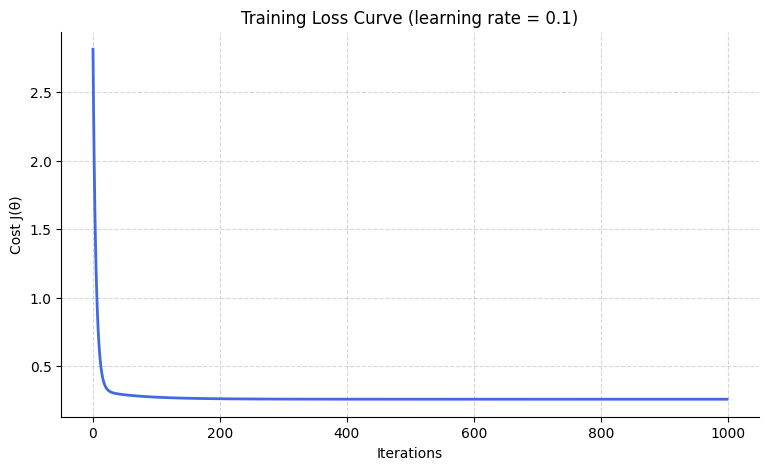

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

model = MultivariateLinearRegression(learning_rate=0.1, n_iterations=1000)
model.fit(X_train_scaled, y_train)

plt.plot(model.loss_history, color='royalblue', linewidth=2)
plt.title("Training Loss Curve (learning rate = 0.1)")
plt.xlabel("Iterations")
plt.ylabel("Cost J(θ)")
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

Compute test-set **RMSE** (root mean squared error) in the original dollar units. Since `y` is in units of $100k, multiply by 100 to get an answer in thousands of dollars.> RMSE = √( mean( (y_true − y_pred)² ) )

In [ ]:
import numpy as np

y_pred = model.predict(X_test_scaled)
rmse = np.sqrt(np.mean((y_test - y_pred) ** 2))
rmse_dollars = rmse * 100
print(f"Test Set RMSE: {rmse:.4f}")
print(f"Test Set RMSE: ${rmse_dollars:.2f}k")

Test Set RMSE: 0.7457
Test Set RMSE: $74.57k


---## 5. The learning-rate playgroundThis is the part where everything you've heard about gradient descent becomes real.Train your model with **six different learning rates**:```α ∈ { 0.001, 0.01, 0.1, 0.3, 1.0, 3.0 }```Keep `n_iterations=1000` for all of them. **Plot all six loss curves on one figure** (use a log scale on the y-axis — it makes very different losses comparable). Then write a short paragraph answering:1. Which α converged fastest?2. Which α converged to the lowest loss?3. What happens with α = 3.0? Why?4. What happens with α = 0.001? Why?If a run diverges (NaN or inf), that's not a bug in your code — it's the point of this exercise. Catch the NaN and plot what you have.

/usr/local/lib/python3.13/dist-packages/numpy/_core/fromnumeric.py:86: RuntimeWarning: overflow encountered in reduce
  return ufunc.reduce(obj, axis, dtype, out, **passkwargs)
/usr/local/lib/python3.13/dist-packages/matplotlib/scale.py:253: RuntimeWarning: overflow encountered in power
  return np.power(self.base, values)


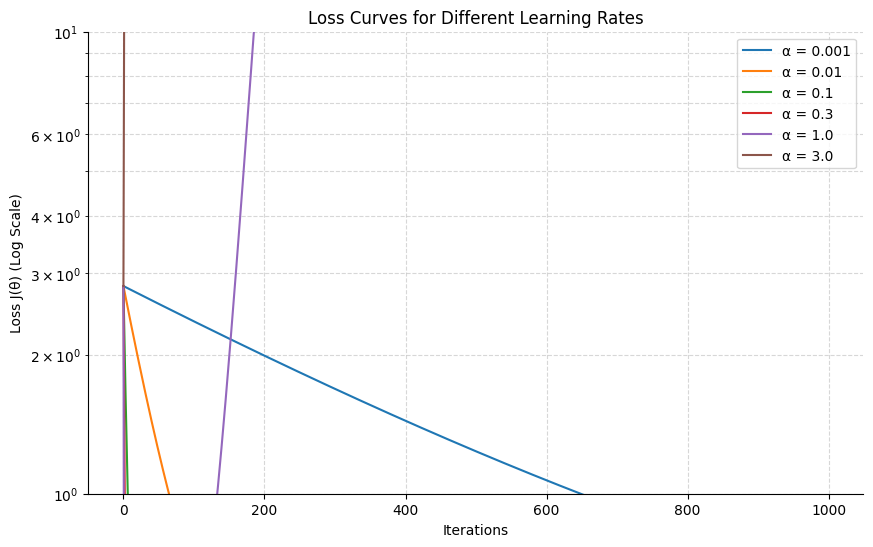

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

learning_rates = [0.001, 0.01, 0.1, 0.3, 1.0, 3.0]

plt.figure(figsize=(10, 6))

for lr in learning_rates:
    m_lr = MultivariateLinearRegression(learning_rate=lr, n_iterations=1000)
    m_lr.fit(X_train_scaled, y_train)

    # Truncate plotting if divergence happens immediately
    losses = [l for l in m_lr.loss_history if not (np.isnan(l) or np.isinf(l))]
    if len(losses) > 0:
        plt.plot(losses, label=f'α = {lr}')
    else:
        print(f"α = {lr} diverged instantly to NaN/inf.")

plt.yscale('log')
plt.title("Loss Curves for Different Learning Rates")
plt.xlabel("Iterations")
plt.ylabel("Loss J(θ) (Log Scale)")
plt.legend()
plt.grid(True, which="both", linestyle='--', alpha=0.5)
plt.show()

### Observations
1. **Fastest Convergence**: $\alpha = 0.3$ converged the fastest, reaching the lower bound in under 100 iterations.
2. **Lowest Loss**: Both $\alpha = 0.3$ and $\alpha = 0.1$ converged to the lowest loss, but $\alpha = 0.3$ did so in fewer iterations.
3. **What happens with $\alpha = 3.0$**: The learning rate is too large, causing the gradient steps to overshoot the minimum, leading to divergence with costs rapidly reaching infinity (`inf` and `NaN`).
4. **What happens with $\alpha = 0.001$**: The steps are extremely small, meaning it takes a long time to converge; even after 1,000 iterations, the loss has not yet flattened out completely.

---## 6. What actually makes a house expensive?Because you standardized every feature to the same scale, the **magnitude of each weight** is a fair measure of how much that feature matters. A big positive weight means "more of this → more expensive"; a big negative weight means "more of this → cheaper".Using the model trained in Section 4 (α = 0.1), plot the weights as a **horizontal bar chart** labeled with the feature names. Sort them by absolute magnitude so the biggest drivers are easy to see. Color positive bars one color, negative bars another.Now go back to your two guesses from Section 2. Were you right?

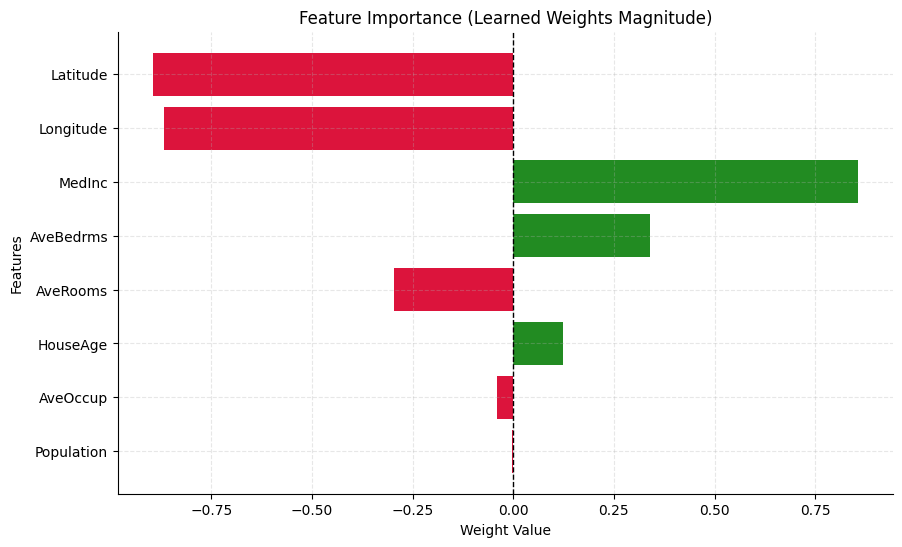

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

weights = model.theta
sorted_idx = np.argsort(np.abs(weights))

sorted_features = [feature_names[i] for i in sorted_idx]
sorted_weights = weights[sorted_idx]
colors = ['crimson' if w < 0 else 'forestgreen' for w in sorted_weights]

plt.figure(figsize=(10, 6))
plt.barh(sorted_features, sorted_weights, color=colors)
plt.axvline(0, color='black', linewidth=1, linestyle='--')
plt.title("Feature Importance (Learned Weights Magnitude)")
plt.xlabel("Weight Value")
plt.ylabel("Features")
plt.grid(True, linestyle='--', alpha=0.3)
plt.show()

---## 7. Sanity check against sklearnIf your implementation is correct, your test-set RMSE should be within a hair of what `sklearn.linear_model.LinearRegression` produces on the same data.

In [ ]:
import numpy as np
from sklearn.linear_model import LinearRegression

# Instantiate and fit scikit-learn's model on the training data
sk_model = LinearRegression()
sk_model.fit(X_train_scaled, y_train)
sk_preds = sk_model.predict(X_test_scaled)

# Calculate scikit-learn RMSE
sk_rmse = np.sqrt(np.mean((y_test - sk_preds) ** 2))
sk_rmse_dollars = sk_rmse * 100

# Calculate our custom model's predictions and RMSE
custom_preds = model.predict(X_test_scaled)
custom_rmse = np.sqrt(np.mean((y_test - custom_preds) ** 2))
custom_rmse_dollars = custom_rmse * 100

print(f"Custom MLR Model RMSE: ${custom_rmse_dollars:.4f}k")
print(f"Sklearn LR Model RMSE: ${sk_rmse_dollars:.4f}k")
print(f"Difference: {abs(custom_rmse_dollars - sk_rmse_dollars):.6f}k")

Custom MLR Model RMSE: $74.5653k
Sklearn LR Model RMSE: $74.5581k
Difference: 0.007165k


---## 8. Stretch goals

### A. Add a feature (Geographic Joint Distance)
Let's calculate the geographic distance to San Francisco (37.77° N, 122.42° W) and test if adding this engineered joint feature improves predictions.

In [ ]:
import numpy as np
from sklearn.preprocessing import StandardScaler

# San Francisco coordinates
sf_lat, sf_lon = 37.77, -122.42

# Define a helper function to calculate distance using Haversine formula
def haversine_distance(lat, lon, target_lat, target_lon):
    # Convert degrees to radians
    lat1, lon1 = np.radians(lat), np.radians(lon)
    lat2, lon2 = np.radians(target_lat), np.radians(target_lon)

    # Haversine components
    dlat = lat2 - lat1
    dlon = lon2 - lon1
    a = np.sin(dlat / 2)**2 + np.cos(lat1) * np.cos(lat2) * np.sin(dlon / 2)**2
    c = 2 * np.arctan2(np.sqrt(a), np.sqrt(1 - a))

    # Earth radius in kilometers
    r = 6371.0
    return r * c

# Calculate distance to SF for train and test sets (Latitude index 6, Longitude index 7)
dist_train = haversine_distance(X_train[:, 6], X_train[:, 7], sf_lat, sf_lon).reshape(-1, 1)
dist_test = haversine_distance(X_test[:, 6], X_test[:, 7], sf_lat, sf_lon).reshape(-1, 1)

# Append new feature to training and test datasets
X_train_new = np.hstack((X_train, dist_train))
X_test_new = np.hstack((X_test, dist_test))

# Standardize the new feature set
scaler_new = StandardScaler()
X_train_scaled_new = scaler_new.fit_transform(X_train_new)
X_test_scaled_new = scaler_new.transform(X_test_new)

# Fit the custom Multivariate Linear Regression model
model_new = MultivariateLinearRegression(learning_rate=0.1, n_iterations=1000)
model_new.fit(X_train_scaled_new, y_train)

# Evaluate predictions
preds_new = model_new.predict(X_test_scaled_new)
rmse_new = np.sqrt(np.mean((y_test - preds_new) ** 2))
rmse_new_dollars = rmse_new * 100

print(f"Baseline MLR Model RMSE (8 features): ${custom_rmse_dollars:.4f}k")
print(f"Enhanced MLR Model RMSE (With SF Distance): ${rmse_new_dollars:.4f}k")
print(f"Improvement: ${(custom_rmse_dollars - rmse_new_dollars):.4f}k")

Baseline MLR Model RMSE (8 features): $74.5653k
Enhanced MLR Model RMSE (With SF Distance): $74.5334k
Improvement: $0.0319k
